## Exercício prático de regressão linear

Instruções: Use o dataset 'datasetCarros.csv' em todos os exercícios.

In [1]:
# Qual dataset de carros???

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import os

# Carregar o dataset e armazenar na variável 'dataset'
dataset = pd.read_csv("datasetCarros.csv")

# Exibir as primeiras linhas para conferir os dados
print(dataset.head())

      Nome   Ano  PrecoVenda  PrecoAtual  KmRodado TipoCombustivel Trasmissao  \
0     ritz  2014        3.35        5.59     27000          Petrol     Manual   
1      sx4  2013        4.75        9.54     43000          Diesel     Manual   
2     ciaz  2017        7.25        9.85      6900          Petrol     Manual   
3  wagon r  2011        2.85        4.15      5200          Petrol     Manual   
4    swift  2014        4.60        6.87     42450          Diesel     Manual   

   Owner  
0      0  
1      0  
2      0  
3      0  
4      0  


# 1
a) Faça um modelo de regressão linear simples utilizando a variável 'KmRodado' para prever a 'PrecoVenda'.<br>

b) Calcule o R2 para o modelo criado.

R² do modelo: -0.0581


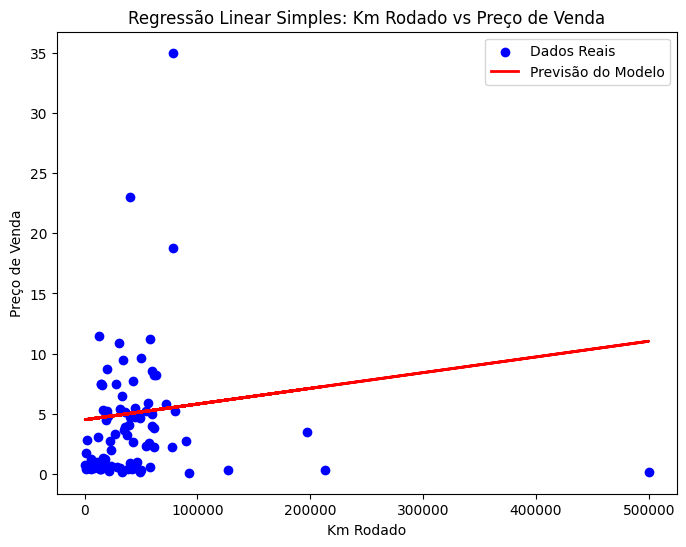

In [14]:
# Selecionar variáveis
X = dataset[['KmRodado']]  # Variável preditora
y = dataset['PrecoVenda']  # Variável alvo

# Dividir dados em treino e teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3)

# Criar e treinar o modelo de regressão linear
modelo = LinearRegression()
modelo.fit(X_train, y_train)

# Fazer previsões
y_pred = modelo.predict(X_test)

# Calcular o coeficiente de determinação R²
r2 = r2_score(y_test, y_pred)
print(f'R² do modelo: {r2:.4f}')

# Visualizar os resultados
plt.figure(figsize=(8, 6))
plt.scatter(X_test, y_test, color='blue', label='Dados Reais')
plt.plot(X_test, y_pred, color='red', linewidth=2, label='Previsão do Modelo')
plt.xlabel('Km Rodado')
plt.ylabel('Preço de Venda')
plt.title('Regressão Linear Simples: Km Rodado vs Preço de Venda')
plt.legend()
plt.show()


# 2
a) Separe o dataset em teste (5%) e treino (95%). Use o método 'train_test_split' do sklearn; configure o parâmetro random_state=10. <br>

b) Treine um modelo de regressão linear múltipla no dataset de treino utilizando todas as variáveis (exceto 'Nome') para prever a 'PrecoVenda' e exiba os coeficientes do modelo.<br>

c) Avalie o modelo encontrado utilizando o dataset de teste. Calcule o R2 e MSE.

In [17]:
from sklearn.metrics import mean_squared_error, r2_score

X = dataset.drop(['Nome', 'PrecoVenda'], axis=1)
y = dataset['PrecoVenda']


categorical_features = ['TipoCombustivel', 'Trasmissao', 'Owner']
X = pd.get_dummies(X, columns=categorical_features, drop_first=True)

# Dividir o dataset em treino (95%) e teste (5%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.05, random_state=10)

# Instanciar e treinar o modelo de regressão linear múltipla
modelo = LinearRegression()
modelo.fit(X_train, y_train)

# Exibir os coeficientes do modelo
print("Coeficientes do modelo:")
for feature, coef in zip(X.columns, modelo.coef_):
    print(f"{feature}: {coef}")
print(f"Intercepto: {modelo.intercept_}")

# Avaliar o modelo no conjunto de teste:
y_pred = modelo.predict(X_test)

# Calcular o coeficiente de determinação R² e o erro quadrático médio (MSE)
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

print("\nAvaliação no conjunto de teste:")
print(f"R²: {r2:.4f}")
print(f"MSE: {mse:.4f}")

Coeficientes do modelo:
Ano: 0.35233004033952464
PrecoAtual: -0.00037283441555105624
KmRodado: -6.4064882978655e-07
TipoCombustivel_Diesel: 5.982893887311503
TipoCombustivel_Petrol: -0.5235117220243569
Trasmissao_Manual: -4.584943654473292
Owner_1: -0.9858549808135662
Owner_3: -2.125080985161785
Intercepto: -701.5256487193897

Avaliação no conjunto de teste:
R²: 0.6287
MSE: 8.6215
